In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
df = pd.read_excel(
    r"C:\Users\MTC\Desktop\RetailPulse\data\processed\retail_clean.xlsx"
)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [3]:
customer_df = df.dropna(
    subset=["Customer ID"]
).copy()

In [4]:
customer_df.shape

(401605, 17)

In [5]:
# Choosing the analysis date as the last invoice date in the dataset
analysis_date = customer_df["InvoiceDate"].max()

print("Analysis date:", analysis_date)

Analysis date: 2011-12-09 12:50:00


In [6]:
# Calculating RFM metrics
# Calculating recency 
last_purchase = (
    customer_df
    .groupby("Customer ID")["InvoiceDate"]
    .max()
)

recency = (
    analysis_date - last_purchase
).dt.days

In [7]:
recency.head()

Customer ID
12346.0    325
12347.0      1
12348.0     74
12349.0     18
12350.0    309
Name: InvoiceDate, dtype: int64

In [8]:
# Calculating frequency 
frequency = (
    customer_df
    .groupby("Customer ID")["Invoice"]
    .nunique()
)

In [9]:
# Calculating monetary

monetary = (
    customer_df
    .groupby("Customer ID")["Revenue"]
    .sum()
)

In [10]:
# Combining RFM metrics into a single DataFrame

rfm = pd.DataFrame({
    "Recency": recency,
    "Frequency": frequency,
    "Monetary": monetary
})

In [11]:
rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,325,2,0.00
12347.0,1,7,4310.00
12348.0,74,4,1797.24
12349.0,18,1,1757.55
12350.0,309,1,334.40


In [12]:
# Inspecting the RFM data
rfm.describe()

,Recency,Frequency,Monetary
count,4372.000000,4372.000000,4372.000000
mean,91.047118,5.075480,1893.535550
std,100.765435,9.338754,8218.695692
min,0.000000,1.000000,-4287.630000
25%,16.000000,1.000000,291.795000
50%,49.000000,3.000000,644.070000
75%,142.000000,5.000000,1608.335000
max,373.000000,248.000000,279489.020000


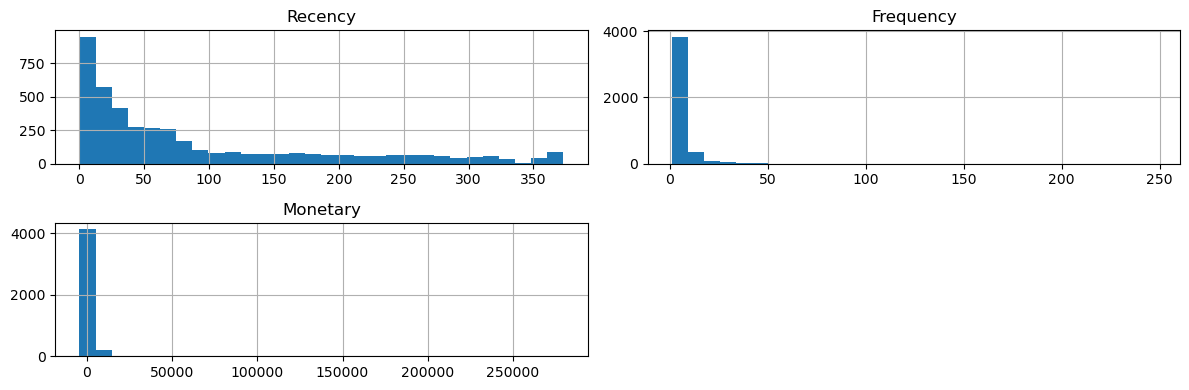

In [13]:
rfm[["Recency", "Frequency", "Monetary"]].hist(
    figsize=(12, 4),
    bins=30
)

plt.tight_layout()
plt.show()

In [14]:
# Transforming data for better understanding

rfm_model = rfm.copy()

rfm_model["Recency"] = np.log1p(
    rfm_model["Recency"]
)

rfm_model["Frequency"] = np.log1p(
    rfm_model["Frequency"]
)

rfm_model["Monetary"] = np.log1p(
    rfm_model["Monetary"].clip(lower=0)
)

In [15]:
rfm_model.describe()

,Recency,Frequency,Monetary
count,4372.000000,4372.000000,4372.000000
mean,3.732268,1.442881,6.484998
std,1.464709,0.736499,1.437272
min,0.000000,0.693147,0.000000
25%,2.833213,0.693147,5.679473
50%,3.912023,1.386294,6.469359
75%,4.962845,1.791759,7.383576
max,5.924256,5.517453,12.540722


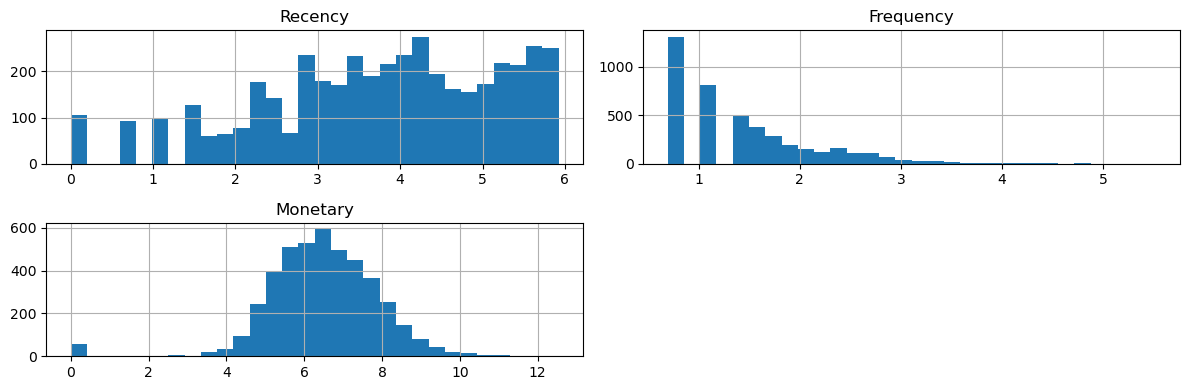

In [16]:
rfm_model.hist(
    figsize=(12, 4),
    bins=30
)

plt.tight_layout()
plt.show()

In [17]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(
    rfm_model
)

In [18]:
rfm_scaled[:5]

array([[ 1.40291653, -0.46749327, -4.51253398],
       [-2.07513467,  0.86440534,  1.31091536],
       [ 0.39959276,  0.22617276,  0.70249795],
       [-0.53793558, -1.01808698,  0.68696759],
       [ 1.36855418, -1.01808698, -0.4659876 ]])

In [19]:
# Clustering using elbow method for K-Means
inertia = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(rfm_scaled)

    inertia.append(model.inertia_)
    

c:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\anaconda\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\anaconda\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass

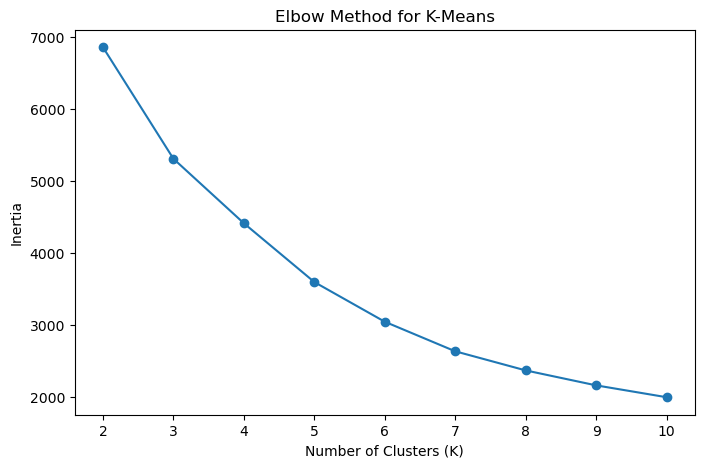

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")

plt.show()

In [21]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    silhouette_scores.append(score)

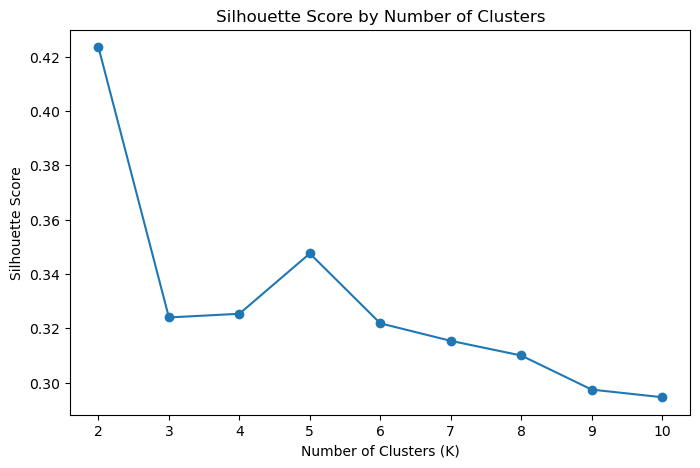

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")

plt.show()

In [23]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

rfm["Segment"] = kmeans.fit_predict(
    rfm_scaled
)

In [24]:
rfm.head()

,Recency,Frequency,Monetary,Segment
Customer ID,,,,
12346.0,325,2,0.00,4
12347.0,1,7,4310.00,1
12348.0,74,4,1797.24,2
12349.0,18,1,1757.55,0
12350.0,309,1,334.40,3


In [25]:
# Grouping customers by segment and calculating average RFM values for each segment

segment_summary = (
    rfm.groupby("Segment")
    [["Recency", "Frequency", "Monetary"]]
    .mean()
    .round(2)
)

segment_summary

,Recency,Frequency,Monetary
Segment,,,
0,15.88,2.42,573.77
1,8.17,17.20,7848.11
2,63.33,5.46,1766.51
3,173.97,1.51,373.45
4,216.79,1.65,-212.06


What each segment tells us

Segment 0 — Recent, low-frequency customers
Customers purchased recently but have placed relatively few orders and generated modest revenue.

Segment 1 — High-value loyal customers
These customers have the highest average frequency and monetary value, and the lowest recency.

Segment 2 — Regular, mid-value customers
These customers purchase more frequently and generate more revenue than Segments 0 and 3, but their latest purchase was less recent.

Segment 3 — Inactive, low-value customers
Their average last purchase was about 174 days ago, with low purchase frequency and spending.

Segment 4 — Long-inactive customers with negative net monetary value
Their average recency is about 217 days, and their monetary value is negative. This may indicate returns, cancellations, or adjustments exceeding recorded positive revenue.

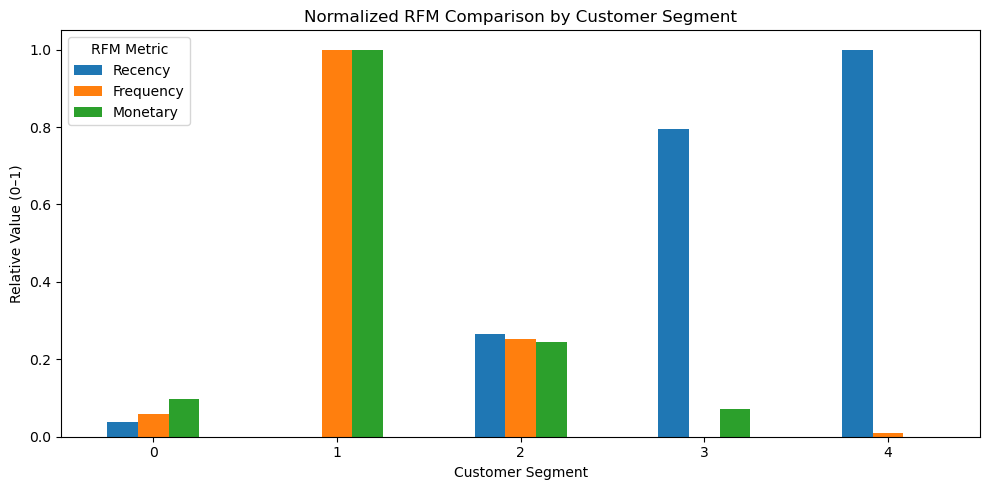

In [26]:
# Visualizing the average RFM values for each segment

segment_summary_normalized = (
    segment_summary - segment_summary.min()
) / (
    segment_summary.max() - segment_summary.min()
)

segment_summary_normalized.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Normalized RFM Comparison by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Relative Value (0–1)")
plt.xticks(rotation=0)
plt.legend(title="RFM Metric")
plt.tight_layout()
plt.show()

In [33]:
rfm.to_excel(
    r"C:\Users\MTC\Desktop\RetailPulse\data\processed\customer_segments.xlsx",
    index=True
)

In [31]:
# Counting customers and their percentages in each segment

segment_counts = rfm["Segment"].value_counts().sort_index()
print(segment_counts)

segment_percentage = (
    rfm["Segment"].value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)
print(segment_percentage)

Segment
0     834
1     664
2    1114
3    1698
4      62
Name: count, dtype: int64
Segment
0    19.08
1    15.19
2    25.48
3    38.84
4     1.42
Name: proportion, dtype: float64


In [32]:
# Summary of each segment

segment_summary = (
    rfm.groupby("Segment")
    .agg(
        CustomerCount=("Recency", "count"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean")
    )
    .round(2)
)

segment_summary

,CustomerCount,AvgRecency,AvgFrequency,AvgMonetary
Segment,,,,
0,834,15.88,2.42,573.77
1,664,8.17,17.20,7848.11
2,1114,63.33,5.46,1766.51
3,1698,173.97,1.51,373.45
4,62,216.79,1.65,-212.06
